In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('spam.csv',encoding="latin-1")

In [3]:
df.drop(["Unnamed: 2","Unnamed: 3","Unnamed: 4"], axis=1,inplace= True)

In [4]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


1.Data Cleaning

In [5]:
df.rename(columns={'v1':'target','v2':'text'},inplace=True)

In [6]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [7]:
df['target']=encoder.fit_transform(df['target'])

In [8]:
df.drop_duplicates(keep='first',inplace=True)

2.EDA

In [9]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

In [10]:
import matplotlib.pyplot as plt

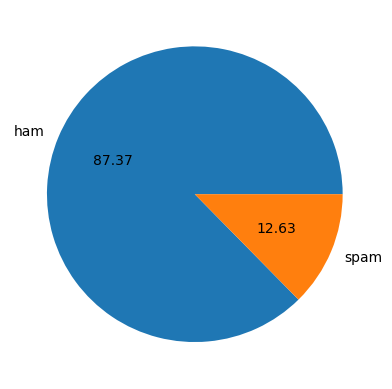

In [11]:
plt.pie(df['target'].value_counts(), labels = ['ham','spam'],autopct='%0.2f')
plt.show()

In [12]:
import nltk

In [ ]:
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/kshitiz/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kshitiz/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
df['num_characters']=df['text'].apply(lambda x:len(x))

In [14]:
df['num_words'] = df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [15]:
df['num_sent'] = df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [16]:
df[df.columns].describe()

,target,num_characters,num_words,num_sent
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.455794,1.965564
std,0.332253,58.236293,13.324758,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [17]:
df[df['target'] == 0][['num_characters','num_words','num_sent']].describe()

,num_characters,num_words,num_sent
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [18]:
df[df['target'] == 1][['num_characters','num_words','num_sent']].describe()

,num_characters,num_words,num_sent
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [19]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

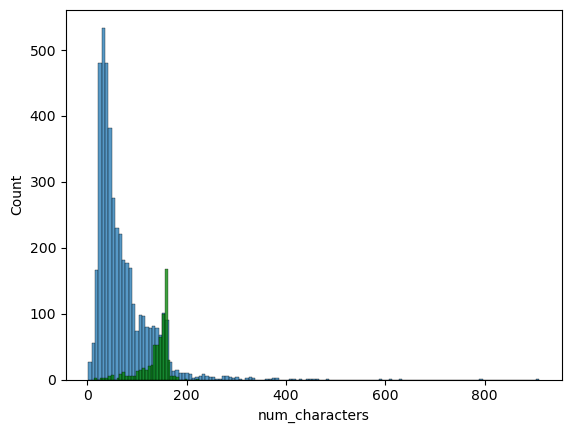

In [20]:
sns.histplot(df[df['target'] == 0]['num_characters'])
sns.histplot(df[df['target'] == 1]['num_characters'],color='green')

<Axes: xlabel='num_words', ylabel='Count'>

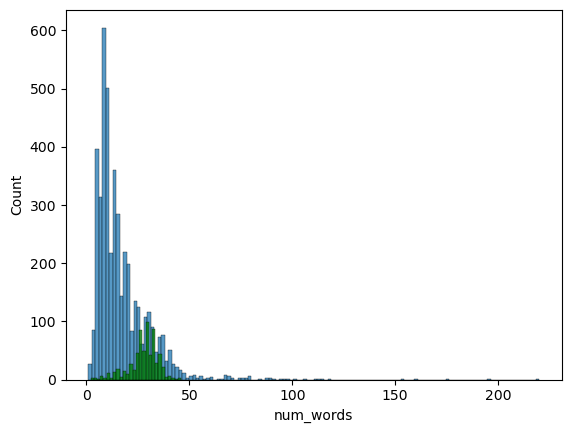

In [21]:
sns.histplot(df[df['target'] == 0]['num_words'])
sns.histplot(df[df['target'] == 1]['num_words'],color='green')

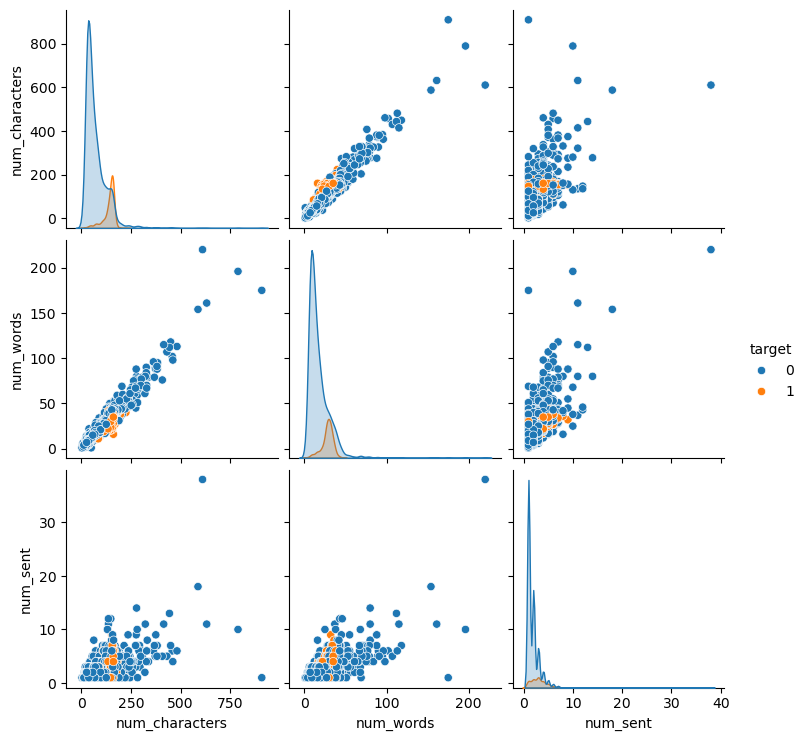

In [22]:
sns.pairplot(df, hue='target')

In [23]:
df[['target','num_characters','num_words','num_sent']].corr()

,target,num_characters,num_words,num_sent
target,1.000000,0.384717,0.262912,0.263939
num_characters,0.384717,1.000000,0.965760,0.624139
num_words,0.262912,0.965760,1.000000,0.679971
num_sent,0.263939,0.624139,0.679971,1.000000


In [24]:
df[['target','num_characters','num_words','num_sent']].cov()

,target,num_characters,num_words,num_sent
target,0.110392,7.443963,1.163964,0.127029
num_characters,7.443963,3391.465845,749.415047,52.650943
num_words,1.163964,749.415047,177.549177,13.124445
num_sent,0.127029,52.650943,13.124445,2.098272


3.Data Preprocessing

In [25]:
import string
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    text = y[:]
    y.clear()
    for i in text:
        y.append(ps.stem(i))
    return y

In [32]:
df['transformed_text'] = df['text'].apply(transform_text)
df['transformed_text']

0       [go, jurong, point, crazi, avail, bugi, n, gre...
1                            [ok, lar, joke, wif, u, oni]
2       [free, entri, 2, wkli, comp, win, fa, cup, fin...
3           [u, dun, say, earli, hor, u, c, alreadi, say]
4            [nah, think, goe, usf, live, around, though]
                              ...                        
5567    [2nd, time, tri, 2, contact, u, pound, prize, ...
5568                          [b, go, esplanad, fr, home]
5569                                [piti, mood, suggest]
5570    [guy, bitch, act, like, interest, buy, someth,...
5571                                   [rofl, true, name]
Name: transformed_text, Length: 5169, dtype: object

In [27]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [28]:
wc_spam = wc.generate(df[df['target'] == 1]['transformed_text'].astype(str).str.cat(sep=" "))

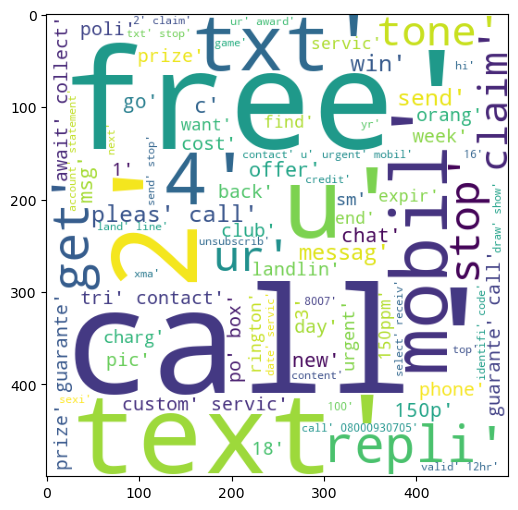

In [29]:
plt.figure(figsize=(12,6))
plt.imshow(wc_spam)

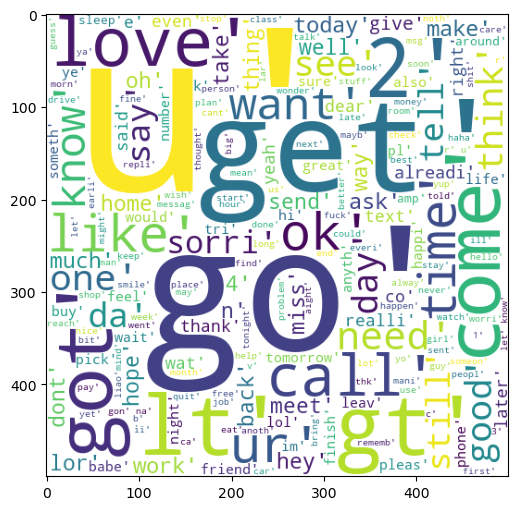

In [30]:
wc_ham = wc.generate(df[df['target'] == 0]['transformed_text'].astype(str).str.cat(sep=" "))
plt.figure(figsize=(12,6))
plt.imshow(wc_ham)

In [31]:
df.head()

,target,text,num_characters,num_words,num_sent,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,"[go, jurong, point, crazi, avail, bugi, n, gre..."
1,0,Ok lar... Joking wif u oni...,29,8,2,"[ok, lar, joke, wif, u, oni]"
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,"[free, entri, 2, wkli, comp, win, fa, cup, fin..."
3,0,U dun say so early hor... U c already then say...,49,13,1,"[u, dun, say, earli, hor, u, c, alreadi, say]"
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,"[nah, think, goe, usf, live, around, though]"


In [33]:
spam_corpus = []
for msg in df[df['target'] == 1]['transformed_text']:
    for word in msg:
        spam_corpus.append(word)
    

<Figure size 1800x1200 with 0 Axes>

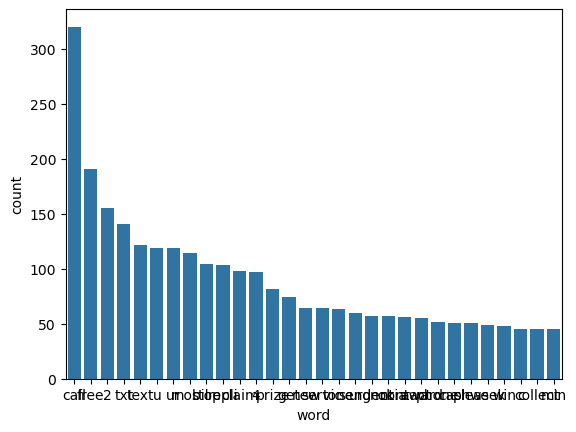

<Figure size 1800x1200 with 0 Axes>

In [34]:
from collections import Counter
sns.barplot(x='word',y='count',data=pd.DataFrame(Counter(spam_corpus).most_common(30),columns=['word','count']))
plt.figure(figsize=(18,12))

In [35]:
ham_corpus = []
for msg in df[df['target'] == 0]['transformed_text']:
    for word in msg:
        ham_corpus.append(word)

In [36]:
len(ham_corpus)

35404

<Figure size 1800x1200 with 0 Axes>

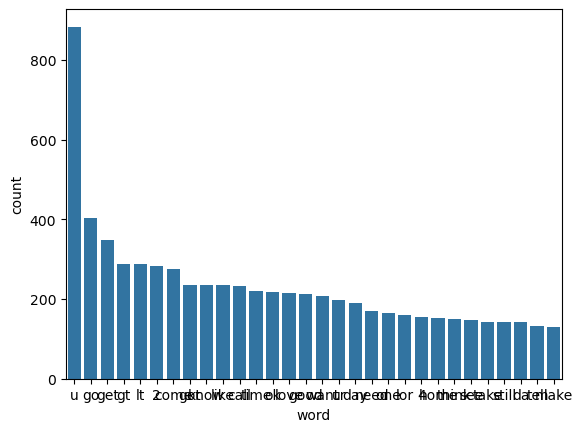

<Figure size 1800x1200 with 0 Axes>

In [37]:
sns.barplot(x='word',y='count',data=pd.DataFrame(Counter(ham_corpus).most_common(30),columns=['word','count']))
plt.figure(figsize=(18,12))

4.Model Building

In [38]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer(max_features=3000)

In [ ]:
df['transformed_jointext'] = df['transformed_text'].apply(lambda x:' '.join(x))

In [ ]:
X = cv.fit_transform(df['transformed_jointext']).toarray()


<class 'pandas.core.series.Series'>
Index: 5169 entries, 0 to 5571
Series name: transformed_jointext
Non-Null Count  Dtype 
--------------  ----- 
5169 non-null   object
dtypes: object(1)
memory usage: 80.8+ KB


In [ ]:
y = df['target'].values

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [ ]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()
etc = ExtraTreesClassifier(n_estimators=50,random_state=2)

In [ ]:
etc.fit(X_train,y_train)
y_pred1 = etc.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))

0.971953578336557
[[888   1]
 [ 28 117]]
0.9915254237288136


In [ ]:
mnb.fit(X_train,y_train)
y_pred2 = mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9738878143133463
[[872  17]
 [ 10 135]]
0.8881578947368421


In [ ]:
bnb.fit(X_train,y_train)
y_pred3 = bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.9661508704061895
[[885   4]
 [ 31 114]]
0.9661016949152542


In [ ]:
gnb.fit(X_train,y_train)
y_pred4 = gnb.predict(X_test)
print(accuracy_score(y_test,y_pred4))
print(confusion_matrix(y_test,y_pred4))
print(precision_score(y_test,y_pred4))

0.8684719535783365
[[772 117]
 [ 19 126]]
0.5185185185185185


In [ ]:
import pickle
pickle.dump(cv,open('vectorizer.pkl','wb'))
pickle.dump(etc,open('model.pkl','wb'))